# PlantAdvisor · 01. Baseline

**Рубежный контроль 1 · Генеративные языковые модели**  
**Задача:** текстовое консультирование по уходу за комнатными растениями и анализу проблем по описанию симптомов.

В этом ноутбуке исследуется **исходная** `Qwen2.5-3B-Instruct`, без SFT. Модель отвечает на фиксированный набор из 30 вопросов; далее вычисляется автоматическая метрика соблюдения формата (Format Pass Rate, FPR). Ответы и параметры запуска сохраняются для последующего сравнения с SFT-моделью.

| Параметр | Значение |
|:--|:--|
| Модель | `Qwen/Qwen2.5-3B-Instruct` |
| GPU при генерации | Google Colab T4 |
| Квантование | 4-bit NF4, double quantization |
| Декодирование | Greedy, `do_sample=False` |
| Максимальная длина ответа | **512 новых токенов** |
| Тестовая выборка | 15 вопросов об уходе + 15 диагностических |
| Основная метрика | Format Pass Rate |

**Зафиксированный результат baseline:** 26/30 (86,7%); уход — 15/15 (100%), диагностика — 11/15 (73,3%). Это реальные данные проведённого GPU-прогона, а не ожидаемые или смоделированные значения. Они также сохранены в `results/baseline/`.

> **Как пользоваться.** По умолчанию `RUN_MODEL = False`: ноутбук воспроизводит анализ **уже сохранённых** результатов без GPU. Для повторного инференса в Colab выберите T4 и установите `RUN_MODEL = True` в следующей ячейке. Новый прогон сохраняется отдельно и не перезаписывает контрольные артефакты.

## 1. Настройки и тестовые вопросы

Тест состоит из 30 фиксированных запросов: 15 `care` (режим ухода) и 15 `diagnosis` (анализ симптомов). Все вопросы имеют стабильные ID `q01`–`q30`. Эта выборка предназначена **только для оценки**, её нельзя добавлять в обучающие данные при SFT.

Для удобства набор вопросов встроен в ноутбук и дублируется в `data/eval_questions.jsonl` репозитория. При повторном запуске данные не генерируются заново.

In [1]:
from pathlib import Path
import hashlib, importlib.metadata, json, random, re, subprocess, sys, time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RUN_MODEL = False  # True: повторить инференс Qwen на GPU T4 в Google Colab
SEED = 42
MODEL_ID = 'Qwen/Qwen2.5-3B-Instruct'
MODEL_REVISION = 'aa8e72537993ba99e69dfaafa59ed015b17504d1'
MAX_NEW_TOKENS = 512
FORMAT_CHECK_VERSION = 'v2_standalone_ordered_nonempty_sections'

random.seed(SEED)

# При работе из клонированного репозитория ищем его корневую папку.
def find_repo_root():
    start = Path.cwd().resolve()
    for directory in [start, *start.parents]:
        if (directory / 'results' / 'baseline' / 'baseline_answers.jsonl').is_file():
            return directory
    return None

REPO_ROOT = find_repo_root()
if not RUN_MODEL and REPO_ROOT is None:
    raise FileNotFoundError(
        'Не найдены сохранённые артефакты. Откройте ноутбук из папки '
        'клонированного plant-advisor или установите RUN_MODEL=True для повторного инференса.'
    )
print('Режим:', 'генерация на GPU' if RUN_MODEL else 'анализ сохранённого baseline')
print('Каталог проекта:', REPO_ROOT if REPO_ROOT else '/content/plant-advisor')

Режим: анализ сохранённого baseline
Каталог проекта: /mnt/data/plant-advisor


In [2]:
EVAL_QUESTIONS = [
  {
    "id": "q01",
    "task": "care",
    "question": "Как ухаживать за монстерой в квартире с восточным окном?"
  },
  {
    "id": "q02",
    "task": "diagnosis",
    "question": "У монстеры желтеют листья, а грунт постоянно влажный. Что проверить?"
  },
  {
    "id": "q03",
    "task": "care",
    "question": "Как понять, что замиокулькас пора поливать зимой?"
  },
  {
    "id": "q04",
    "task": "diagnosis",
    "question": "У фикуса Бенджамина резко опадают листья после перестановки. Что могло случиться?"
  },
  {
    "id": "q05",
    "task": "care",
    "question": "Какие условия нужны спатифиллуму, чтобы он нормально рос?"
  },
  {
    "id": "q06",
    "task": "diagnosis",
    "question": "У спатифиллума коричневые кончики листьев. В чём могут быть причины?"
  },
  {
    "id": "q07",
    "task": "care",
    "question": "Можно ли держать сансевиерию в глубине комнаты без прямого света?"
  },
  {
    "id": "q08",
    "task": "diagnosis",
    "question": "У сансевиерии основание листа стало мягким и водянистым. Что предпринять?"
  },
  {
    "id": "q09",
    "task": "care",
    "question": "Как пересадить молодой хлорофитум, чтобы не повредить корни?"
  },
  {
    "id": "q10",
    "task": "diagnosis",
    "question": "У хлорофитума побледнели листья и замедлился рост. Что проверить?"
  },
  {
    "id": "q11",
    "task": "care",
    "question": "Как ухаживать за орхидеей фаленопсис после цветения?"
  },
  {
    "id": "q12",
    "task": "diagnosis",
    "question": "У фаленопсиса сморщились листья, а корни в прозрачном горшке серебристые. Как разобраться?"
  },
  {
    "id": "q13",
    "task": "care",
    "question": "Как выбрать место для кактуса зимой в квартире?"
  },
  {
    "id": "q14",
    "task": "diagnosis",
    "question": "У кактуса появилась мягкая тёмная зона около основания. Какие действия безопасны?"
  },
  {
    "id": "q15",
    "task": "care",
    "question": "Как правильно поливать алоэ в разные сезоны?"
  },
  {
    "id": "q16",
    "task": "diagnosis",
    "question": "Листья алоэ стали тонкими и начали скручиваться. Какие причины возможны?"
  },
  {
    "id": "q17",
    "task": "care",
    "question": "Что учитывать при уходе за калатеей в сухой квартире?"
  },
  {
    "id": "q18",
    "task": "diagnosis",
    "question": "У калатеи скручиваются листья и сохнут края. Что сначала проверить?"
  },
  {
    "id": "q19",
    "task": "care",
    "question": "Когда и чем подкармливать пеларгонию на подоконнике?"
  },
  {
    "id": "q20",
    "task": "diagnosis",
    "question": "У пеларгонии желтеют нижние листья и отваливаются бутоны. Как действовать?"
  },
  {
    "id": "q21",
    "task": "care",
    "question": "Как подобрать субстрат для антуриума при пересадке?"
  },
  {
    "id": "q22",
    "task": "diagnosis",
    "question": "У антуриума на листьях появились тёмные пятна, но причина неизвестна. Что нужно уточнить?"
  },
  {
    "id": "q23",
    "task": "care",
    "question": "Как ухаживать за драценой зимой рядом с батареей?"
  },
  {
    "id": "q24",
    "task": "diagnosis",
    "question": "У драцены сохнут кончики листьев. Полив регулярный, других данных нет. Что спросить?"
  },
  {
    "id": "q25",
    "task": "care",
    "question": "Что нужно знать о выращивании толстянки на северном окне?"
  },
  {
    "id": "q26",
    "task": "diagnosis",
    "question": "У толстянки листья стали мягкими, хотя почва сырая. В чём риск?"
  },
  {
    "id": "q27",
    "task": "care",
    "question": "Как обеспечить уход за плющом комнатным в летнюю жару?"
  },
  {
    "id": "q28",
    "task": "diagnosis",
    "question": "На листьях плюща появилась мелкая светлая крапчатость и тонкая паутинка. Что проверить?"
  },
  {
    "id": "q29",
    "task": "care",
    "question": "Как выбрать горшок и дренаж для диффенбахии?"
  },
  {
    "id": "q30",
    "task": "diagnosis",
    "question": "У диффенбахии внезапно поникли листья, хотя вчера выглядела нормально. Каков порядок проверки?"
  }
]

assert len(EVAL_QUESTIONS) == 30
assert len({q['id'] for q in EVAL_QUESTIONS}) == 30
assert sum(q['task'] == 'care' for q in EVAL_QUESTIONS) == 15
assert sum(q['task'] == 'diagnosis' for q in EVAL_QUESTIONS) == 15

question_blob = json.dumps(EVAL_QUESTIONS, ensure_ascii=False,
                           sort_keys=True, separators=(',', ':'))
QUESTIONS_SHA256 = hashlib.sha256(question_blob.encode('utf-8')).hexdigest()
print('Вопросов:', len(EVAL_QUESTIONS))
print('Контрольная сумма:', QUESTIONS_SHA256[:16] + '…')
display(pd.DataFrame(EVAL_QUESTIONS).head(6))

Вопросов: 30
Контрольная сумма: 5e7b370d15fb806c…


,id,task,question
0,q01,care,Как ухаживать за монстерой в квартире с восточ...
1,q02,diagnosis,"У монстеры желтеют листья, а грунт постоянно в..."
2,q03,care,"Как понять, что замиокулькас пора поливать зимой?"
3,q04,diagnosis,У фикуса Бенджамина резко опадают листья после...
4,q05,care,"Какие условия нужны спатифиллуму, чтобы он нор..."
5,q06,diagnosis,У спатифиллума коричневые кончики листьев. В ч...


## 2. Промпт и инференс

Системный промпт задаёт две роли ответа. Для `care`: **«Условия» → «Рекомендации»**. Для `diagnosis`: **«Возможные причины» → «Что проверить» → «Что делать»**. Неопределённость не должна подаваться как установленный диагноз.

Используем 4-битные веса NF4 для снижения потребления GPU-памяти. `max_new_tokens=512` ограничивает только число вновь сгенерированных токенов. Генерация жадная (`do_sample=False`), без случайной выборки.

Загрузка модели выполняется **только** в режиме `RUN_MODEL = True`; для просмотра существующих метрик GPU не требуется.

In [3]:
SYSTEM_PROMPT = 'Ты русскоязычный консультант по домашним растениям.\nДавай конкретные, практически полезные и осторожные рекомендации.\n\nЕсли пользователь спрашивает об уходе, выдай ответ строго с разделами\nв указанном порядке:\nУсловия\nРекомендации\n\nЕсли пользователь описывает симптомы или проблему с растением,\nвыдай ответ строго с разделами в указанном порядке:\nВозможные причины\nЧто проверить\nЧто делать\n\nПиши каждый заголовок на отдельной строке; после заголовка обязательно\nдобавляй содержательный текст или пункты. Не используй заголовок как часть\nпредложения. Не выдавай предположение за установленный диагноз.\nКогда информации недостаточно, предложи, какие данные нужно уточнить.\nИзбегай опасных, безосновательных и чрезмерно категоричных советов.'
print('System prompt зафиксирован. Символов:', len(SYSTEM_PROMPT))

System prompt зафиксирован. Символов: 738


In [4]:
if RUN_MODEL:
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '-q',
        'transformers>=4.45,<5', 'accelerate>=1.0,<2',
        'bitsandbytes>=0.45,<1', 'safetensors>=0.4'
    ])
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
    assert torch.cuda.is_available(), 'Для инференса выберите среду выполнения T4 GPU.'
    random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    print('GPU:', torch.cuda.get_device_name(0))

    quant_cfg = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type='nf4',
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.float16,
    )
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        device_map='auto',
        quantization_config=quant_cfg,
        torch_dtype=torch.float16,
    )
    model.eval()
    print('Загружена модель:', MODEL_ID)
else:
    print('Модель не загружена: используется сохранённый baseline.')

Модель не загружена: используется сохранённый baseline.


In [5]:
if RUN_MODEL:
    @torch.inference_mode()
    def answer_question(question):
        messages = [
            {'role': 'system', 'content': SYSTEM_PROMPT},
            {'role': 'user', 'content': question},
        ]
        inputs = tokenizer.apply_chat_template(
            messages, add_generation_prompt=True,
            tokenize=True, return_tensors='pt'
        ).to(next(model.parameters()).device)
        generated = model.generate(
            inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
            num_beams=1,
            pad_token_id=tokenizer.eos_token_id,
        )
        tokens = generated[0, inputs.shape[-1]:]
        return tokenizer.decode(tokens, skip_special_tokens=True).strip()

    for item in EVAL_QUESTIONS[:2]:
        start = time.perf_counter()
        answer = answer_question(item['question'])
        print(f"\n{item['id']} · {item['question']}  ({time.perf_counter()-start:.1f} c)")
        print(answer)
else:
    saved = REPO_ROOT / 'results' / 'baseline' / 'quick_run.jsonl'
    quick = [json.loads(s) for s in saved.read_text(encoding='utf-8').splitlines() if s.strip()]
    print('Сохранённые примеры исходной генерации:')
    for item in quick:
        print(f"\n{item['id']} · {item['question']}")
        print(item['answer'][:750] + ('…' if len(item['answer']) > 750 else ''))

Сохранённые примеры исходной генерации:

q01 · Как ухаживать за монстерой в квартире с восточным окном?
Условия:
- Свет: Монстеру хорошо светить, но не переносит прямые солнечные лучи. В идеале она будет расти под восточным окном, где солнце светит мягко и равномерно.
- Технические параметры: Оптимальная температура для монстеры - 18-24°C. Она также может расти при температуре до 30°C, но в этом случае требуется повышенное увлажнение воздуха.
- Влажность: Монстеру можно выращивать в помещении с влажным воздухом, но она также может расти в сухом воздухе. Важно регулярно поливать, чтобы почва была всегда слегка влажной, но не мокрой.
- Периодичность полива: Поливайте монстеру, когда верхний слой почвы станет сухой. В жаркое время года поливайте чаще, а в холодное время года реже. Проверьте, не слишком ли влажна почва перед поливом.
- Общие треб…

q02 · У монстеры желтеют листья, а грунт постоянно влажный. Что проверить?
Возможные причины:
- Неправильное освещение
- Плохая подкисленность 

## 3. Автоматическая проверка: Format Pass Rate

**Цель:** измерить, как часто ответ содержит обязательные разделы в правильном порядке и с непустым содержимым. Дополнительные разделы допустимы, если обязательная структура сохранена. Варианты Markdown-оформления заголовков допускаются.

Для каждого ответа `format_ok ∈ {0,1}`; итоговая метрика — среднее этих значений:

\[\mathrm{FPR} = \frac{N_{\text{прошедших проверку}}}{N_{\text{всех ответов}}}.\]

Метрика **не оценивает фактическую правильность или полезность** рекомендаций. Эти аспекты оцениваются отдельно в этапе LLM-as-judge.

In [6]:
EXPECTED_SECTIONS = {
    'care': ['условия', 'рекомендации'],
    'diagnosis': ['возможные причины', 'что проверить', 'что делать'],
}


def normalize_heading(line):
    """Заголовок на отдельной строке: допускаем Markdown-разметку и нумерацию."""
    cleaned = line.strip().casefold().replace('ё', 'е')
    cleaned = re.sub(r'^#{1,6}\s*', '', cleaned)
    cleaned = re.sub(r'^\d{1,2}[.)]\s*', '', cleaned)
    cleaned = re.sub(r'[*_`]', '', cleaned).strip()
    return cleaned.removesuffix(':').strip()


def format_check(text, task):
    if task not in EXPECTED_SECTIONS:
        raise ValueError(f'Неизвестный тип запроса: {task}')
    expected = EXPECTED_SECTIONS[task]
    lines = text.splitlines()
    detected = [(i, normalize_heading(s)) for i, s in enumerate(lines)
                if normalize_heading(s) in expected]
    headings = [h for _, h in detected]
    missing = [h for h in expected if h not in headings]
    duplicates = sorted({h for h in headings if headings.count(h) > 1})
    ordered = headings == expected
    empty = []
    for j, (line_index, heading) in enumerate(detected):
        next_index = detected[j + 1][0] if j + 1 < len(detected) else len(lines)
        body = lines[line_index+1:next_index]
        if not any(x.strip() for x in body):
            empty.append(heading)
    return {
        'format_ok': not missing and not duplicates and ordered and not empty,
        'section_hits': len(expected) - len(missing),
        'sections_total': len(expected),
        'missing': missing,
        'out_of_order': not ordered and not missing and not duplicates,
        'duplicate_sections': duplicates,
        'empty_sections': empty,
    }



# Контрольные случаи для функции проверки
assert format_check('Условия\n- Свет.\nРекомендации\n- Полив.', 'care')['format_ok']
assert format_check('Возможные причины\n- Перелив.\nЧто проверить\n- Грунт.\nЧто делать\n- Проверить дренаж.', 'diagnosis')['format_ok']
assert not format_check('В этих условиях рекомендации зависят от растения.', 'care')['format_ok']
assert not format_check('Рекомендации\n- Полив.\nУсловия\n- Свет.', 'care')['format_ok']
assert not format_check('Условия\nРекомендации\n- Полив.', 'care')['format_ok']
print('Автоматическая проверка прошла тесты.')

Автоматическая проверка прошла тесты.


## 4. Полный прогон и сохранение артефактов

В режиме генерации задаём модели **все 30 вопросов**. После каждого ответа сохраняем запись в JSONL, чтобы прогресс не потерялся при отключении Colab. Новый прогон хранится в `results/reproduced/<run_id>/` и не перезаписывает зафиксированные результаты `results/baseline/`.

В режиме просмотра полный набор берётся непосредственно из результатов исходного GPU-прогона.

In [7]:
if RUN_MODEL:
    LIB_VERSIONS = {p: importlib.metadata.version(p) for p in
        ['transformers', 'accelerate', 'bitsandbytes', 'huggingface-hub', 'safetensors']}
    LIB_VERSIONS['torch'] = torch.__version__
    config = {
        'experiment': 'plant_advisor_baseline',
        'model_id': MODEL_ID,
        'model_revision': MODEL_REVISION,
        'system_prompt': SYSTEM_PROMPT,
        'max_new_tokens': MAX_NEW_TOKENS,
        'decoding': {'do_sample': False, 'num_beams': 1},
        'quantization': {'bits': 4, 'type': 'nf4', 'double_quant': True,
                         'compute_dtype': 'float16'},
        'seed': SEED,
        'question_sha256': QUESTIONS_SHA256,
        'format_check_version': FORMAT_CHECK_VERSION,
        'library_versions': LIB_VERSIONS,
    }
    config_raw = json.dumps(config, ensure_ascii=False, sort_keys=True,
                            separators=(',', ':'))
    run_id = hashlib.sha256(config_raw.encode('utf-8')).hexdigest()[:16]
    work_root = REPO_ROOT if REPO_ROOT else Path('/content/plant-advisor')
    result_dir = work_root / 'results' / 'reproduced' / run_id
    result_dir.mkdir(parents=True, exist_ok=True)
    config_path = result_dir / 'config.json'
    if config_path.exists():
        assert json.loads(config_path.read_text(encoding='utf-8')) == config,             'Конфликт конфигурации в папке результатов'
    else:
        config_path.write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')

    answers_path = result_dir / 'baseline_answers.jsonl'
    previous = {}
    if answers_path.exists():
        for line in answers_path.read_text(encoding='utf-8').splitlines():
            if not line.strip():
                continue
            saved = json.loads(line)
            assert saved['run_id'] == run_id
            assert saved['id'] not in previous
            matching = next((q for q in EVAL_QUESTIONS if q['id'] == saved['id']), None)
            assert matching is not None and all(saved[k] == matching[k]
                                                for k in ('id', 'task', 'question'))
            previous[saved['id']] = saved

    print(f'Сохранено ответов: {len(previous)}/{len(EVAL_QUESTIONS)}')
    for idx, item in enumerate(EVAL_QUESTIONS, 1):
        if item['id'] in previous:
            continue
        started = time.perf_counter()
        answer = answer_question(item['question'])
        evaluation = format_check(answer, item['task'])
        record = {
            **item, 'answer': answer,
            'seconds': round(time.perf_counter() - started, 2),
            **evaluation, 'run_id': run_id,
            'model_id': MODEL_ID, 'model_revision': MODEL_REVISION,
        }
        with answers_path.open('a', encoding='utf-8') as f:
            f.write(json.dumps(record, ensure_ascii=False) + '\n')
        print(f"{idx:02d}/30  {item['id']}  format_ok={evaluation['format_ok']}")
else:
    result_dir = REPO_ROOT / 'results' / 'baseline'
    answers_path = result_dir / 'baseline_answers.jsonl'
    print('Используется зафиксированный прогон:', result_dir)

records = [json.loads(s) for s in answers_path.read_text(encoding='utf-8').splitlines()
           if s.strip()]
assert len(records) == 30 and len({r['id'] for r in records}) == 30
expected = {q['id']: q for q in EVAL_QUESTIONS}
assert all(r['id'] in expected and r['question'] == expected[r['id']]['question']
           and r['task'] == expected[r['id']]['task'] for r in records)
assert all(format_check(r['answer'], r['task'])['format_ok'] == r['format_ok']
           for r in records)
print('Проверено 30 уникальных ответов, метки формата согласованы.')

Используется зафиксированный прогон: /mnt/data/plant-advisor/results/baseline
Проверено 30 уникальных ответов, метки формата согласованы.


## 5. Результаты

Вычисляем FPR отдельно для вопросов по уходу и диагностике. Также приводим среднее время ответа, число присутствующих обязательных разделов и примеры не прошедших форматную проверку ответов. Оценка содержания **не включена** в FPR.

In [8]:
df = pd.DataFrame(records).sort_values('id').reset_index(drop=True)
summary = (df.groupby('task', as_index=False)
           .agg(count=('format_ok', 'size'), pass_rate=('format_ok', 'mean'),
                avg_section_hits=('section_hits','mean'),
                avg_seconds=('seconds','mean')))
summary = pd.concat([summary, pd.DataFrame([{
    'task':'ALL', 'count':len(df),
    'pass_rate':float(df['format_ok'].mean()),
    'avg_section_hits':float(df['section_hits'].mean()),
    'avg_seconds':float(df['seconds'].mean()),
}])], ignore_index=True)
print('Format Pass Rate:', f"{df['format_ok'].mean():.1%}")
display(summary.style.format({'pass_rate':'{:.1%}',
                              'avg_section_hits':'{:.2f}',
                              'avg_seconds':'{:.1f}'}))

failures = df.loc[~df['format_ok'], ['id', 'task', 'missing']]
print('Не прошли проверку:')
display(failures)

Format Pass Rate: 86.7%


,task,count,pass_rate,avg_section_hits,avg_seconds
0,care,15,100.0%,2.00,20.9
1,diagnosis,15,73.3%,2.67,18.6
2,ALL,30,86.7%,2.33,19.7


Не прошли проверку:


,id,task,missing
3,q04,diagnosis,"[что проверить, что делать]"
15,q16,diagnosis,[что делать]
17,q18,diagnosis,[что делать]
25,q26,diagnosis,[что делать]


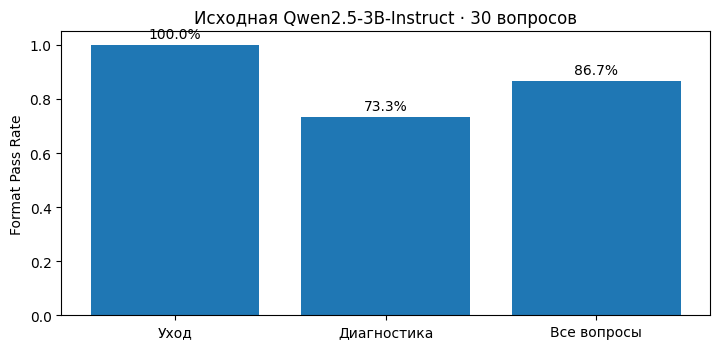

In [9]:
fig, ax = plt.subplots(figsize=(7.3, 3.6))
ax.bar(['Уход', 'Диагностика', 'Все вопросы'],
       [float(summary.loc[summary.task == task, 'pass_rate'].iloc[0])
        for task in ('care', 'diagnosis', 'ALL')])
ax.set_ylim(0, 1.05)
ax.set_ylabel('Format Pass Rate')
ax.set_title('Исходная Qwen2.5-3B-Instruct · 30 вопросов')
for bar in ax.patches:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.015,
            f'{bar.get_height():.1%}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

if RUN_MODEL:
    df.to_csv(result_dir/'baseline_answers.csv', index=False, encoding='utf-8-sig')
    summary.to_csv(result_dir/'baseline_metrics.csv', index=False, encoding='utf-8-sig')
    fig.savefig(result_dir/'baseline_format_rate.png', dpi=160, bbox_inches='tight')
    print('Сохранены ответы, сводка и график:', result_dir)

## 6. Качественный разбор и ограничения

Автоматическая проверка выявляет только отклонения от структуры ответа. Анализ сохранённых генераций дополнительно показывает содержательные ошибки:

| ID | Наблюдение |
|:--|:--|
| `q03` | Рекомендация использовать холодную воду для полива замиокулькаса. |
| `q07` | Совет поддерживать постоянно влажный грунт у сансевиерии. |
| `q23` | Утверждение, что близость батареи повышает влажность воздуха. |
| `q28` | Ошибочное название вредителя «паутинный мох». |
| `q29` | Посторонний SQL-фрагмент в рекомендации по выбору горшка. |

Эти наблюдения иллюстрируют ограничения исходной модели; они не заменяют полноценную оценку фактической правильности. На следующем этапе ответы будут оценены отдельной LLM-as-judge по согласованным критериям.

**Ограничения эксперимента:** небольшой тест (30 вопросов), заданная структура ответов и одна автоматическая метрика. Значение FPR не следует интерпретировать как точность диагностики растений. При сравнении с SFT-моделью нужно использовать те же вопросы, системный промпт, параметры генерации и правила оценки.

## 7. Артефакты и воспроизводимость

Зафиксированные результаты доступны в репозитории:

- `data/eval_questions.jsonl` — 30 тестовых вопросов;
- `results/baseline/baseline_answers.jsonl` — полные неотредактированные ответы;
- `results/baseline/baseline_answers.csv` — таблица по вопросам;
- `results/baseline/baseline_metrics.csv` — сводка метрик;
- `results/baseline/baseline_format_rate.png` — график;
- `results/baseline/config.json` — точная конфигурация и ревизия модели;
- `results/baseline/pip_freeze.txt` — версии библиотек исходного Colab-прогона.

**Запуск на Colab T4:** откройте ноутбук, установите `RUN_MODEL = True` в разделе 1 и выполните все ячейки. Результаты будут созданы в `results/reproduced/<run_id>/` в файловой системе Colab. Поскольку она временная, после генерации сохраните результат в ZIP (ячейка ниже) или на Google Drive. При точном воспроизведении результаты могут не совпасть побуквенно на другом окружении, поэтому сохранены исходные ответы и версии.

In [10]:
if RUN_MODEL:
    import shutil
    zip_target = Path('/content/plant-advisor-baseline-reproduced.zip')
    shutil.make_archive(str(zip_target.with_suffix('')), 'zip',
                        root_dir=result_dir.parent, base_dir=result_dir.name)
    print('ZIP с результатами:', zip_target)
    try:
        from google.colab import files
        files.download(str(zip_target))
    except ImportError:
        print('Скачайте архив вручную из указанной папки.')
else:
    recorded = json.loads((result_dir/'config.json').read_text(encoding='utf-8'))
    assert recorded['max_new_tokens'] == MAX_NEW_TOKENS
    assert recorded['model_id'] == MODEL_ID
    assert recorded['model_revision'] == MODEL_REVISION
    assert recorded['system_prompt'] == SYSTEM_PROMPT
    assert recorded['question_sha256'] == QUESTIONS_SHA256
    print('Конфигурация сохранённого baseline проверена.')
    print('Run ID: 58f7174a5f13e79c')
    print('Артефакты:', result_dir)

Конфигурация сохранённого baseline проверена.
Run ID: 58f7174a5f13e79c
Артефакты: /mnt/data/plant-advisor/results/baseline
